# CLS-03 & CLS-04: Customer Churn Modeling, Cross-Validation & Evaluation
**Project:** Data Mining 3-Task Production System (Classification Task 4: Customer Churn Prediction)  
**Owner:** Rovan (Classification Modeling Engineer)  
**Pipeline:** Zero-Leakage `ImbPipeline(ColumnTransformer -> SMOTE -> Classifier)`

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src.classification.preprocessing import load_and_clean_raw, detect_outliers_iqr, prepare_churn_data
from src.classification.model import train_and_compare_models, predict_churn
from src.classification.evaluation import evaluate_classification
from src.classification.predict import predict_new_customer

## 1. Verify Zero-Leakage Preprocessing Pipeline (`CLS-02`)

In [2]:
DATA_PATH = "../datasets/classification/raw_telco_churn.csv"
df_clean = load_and_clean_raw(DATA_PATH)
print(f"Cleaned shape (customerID dropped, duplicates checked): {df_clean.shape}")
display(detect_outliers_iqr(df_clean))

X_tr, X_te, y_tr, y_te, prep = prepare_churn_data(DATA_PATH, apply_smote=True)
assert X_tr.shape[0] == y_tr.shape[0]
assert not np.isnan(X_tr).any() and not np.isnan(X_te).any()
print(f"Train Shape (after SMOTE): {X_tr.shape}, Class Balance: {np.bincount(y_tr)}")
print(f"Test Shape (Unseen, NO SMOTE): {X_te.shape}, Class Balance: {np.bincount(y_te)}")

Cleaned shape (customerID dropped, duplicates checked): (7043, 20)


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Pct
0,tenure,9.00,55.00,46.00,-60.00,124.00,0,0.0
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0,0.0
2,TotalCharges,401.45,3794.74,3393.29,-4688.48,8884.67,0,0.0


Train Shape (after SMOTE): (8278, 30), Class Balance: [4139 4139]
Test Shape (Unseen, NO SMOTE): (1409, 30), Class Balance: [1035  374]


## 2. Train & Compare 3 Models with 5-Fold Stratified Cross-Validation (`CLS-03`)

In [3]:
MODEL_OUT = "../models/classification/churn_pipeline.pkl"
PREP_OUT = "../models/classification/preprocessor.pkl"
RESULTS_DIR = "../results/classification"

best_pipeline, best_name, X_train, X_test, y_train, y_test, comparison_df, fitted_models = train_and_compare_models(
    data_path=DATA_PATH,
    model_output_path=MODEL_OUT,
    preprocessor_output_path=PREP_OUT,
    results_dir=RESULTS_DIR
)
display(comparison_df)

[Logistic Regression] 5-Fold CV F1: 0.6315 | CV ROC-AUC: 0.8447 | Test F1: 0.6189 | Test Recall: 0.7968 | Test ROC-AUC: 0.8400


[Random Forest] 5-Fold CV F1: 0.6326 | CV ROC-AUC: 0.8443 | Test F1: 0.6276 | Test Recall: 0.7299 | Test ROC-AUC: 0.8432


[XGBoost] 5-Fold CV F1: 0.6315 | CV ROC-AUC: 0.8459 | Test F1: 0.6137 | Test Recall: 0.6818 | Test ROC-AUC: 0.8430

Champion Model Selected: Random Forest (5-Fold CV F1 = 0.6326)
Saved pipeline artifact -> ../models/classification/churn_pipeline.pkl


,Model,CV_5Fold_Accuracy,CV_5Fold_Precision,CV_5Fold_Recall,CV_5Fold_F1,CV_5Fold_ROC_AUC,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7806,0.5694,0.7117,0.6326,0.8443,0.7700,0.5504,0.7299,0.6276,0.8432
1,Logistic Regression,0.7552,0.5260,0.7906,0.6315,0.8447,0.7395,0.5059,0.7968,0.6189,0.8400
2,XGBoost,0.7879,0.5860,0.6849,0.6315,0.8459,0.7722,0.5580,0.6818,0.6137,0.8430


## 3. Compute All 6 Evaluation Metrics & Generate Visualizations (`CLS-04`)

Champion Evaluation Metrics on Held-Out Test Set:
  Accuracy: 0.7700496806245565
  Precision: 0.5504032258064516
  Recall: 0.7299465240641712
  F1-Score: 0.6275862068965518
  ROC-AUC: 0.8431682554444703
  Confusion Matrix: [[812, 223], [101, 273]]
  TN: 812
  FP: 223
  FN: 101
  TP: 273

--- confusion_matrix.png ---


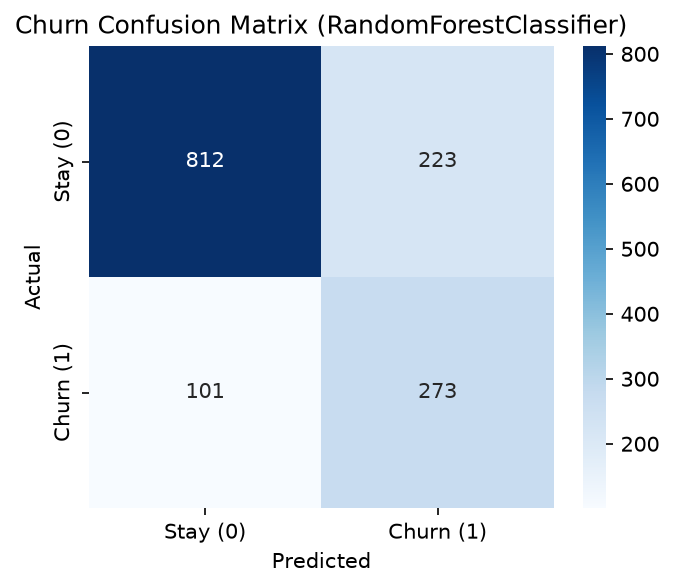


--- roc_curve.png ---


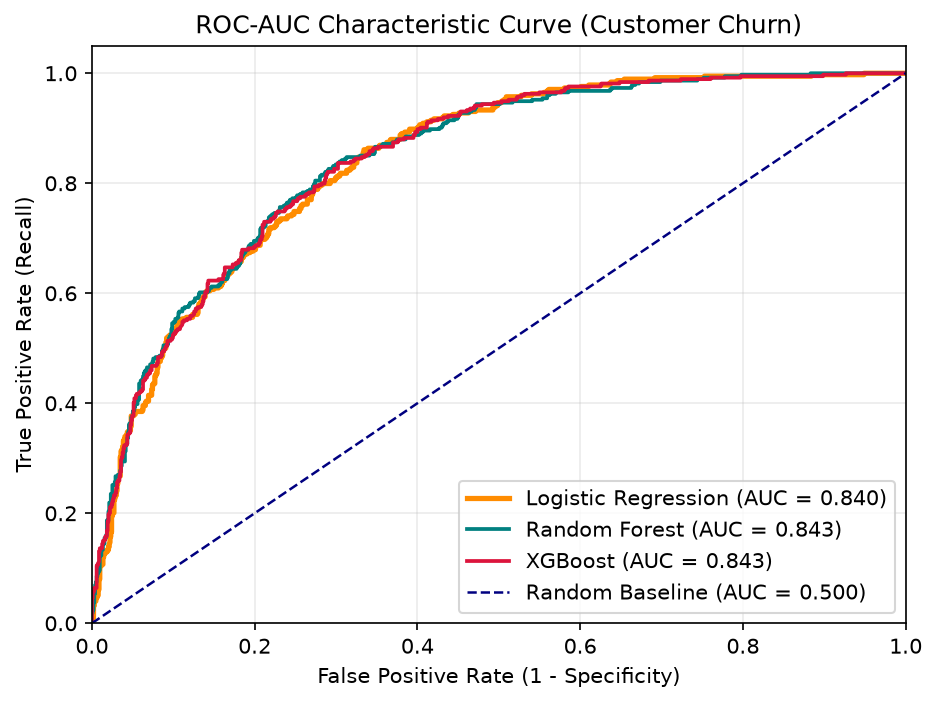


--- predicted_vs_actual.png ---


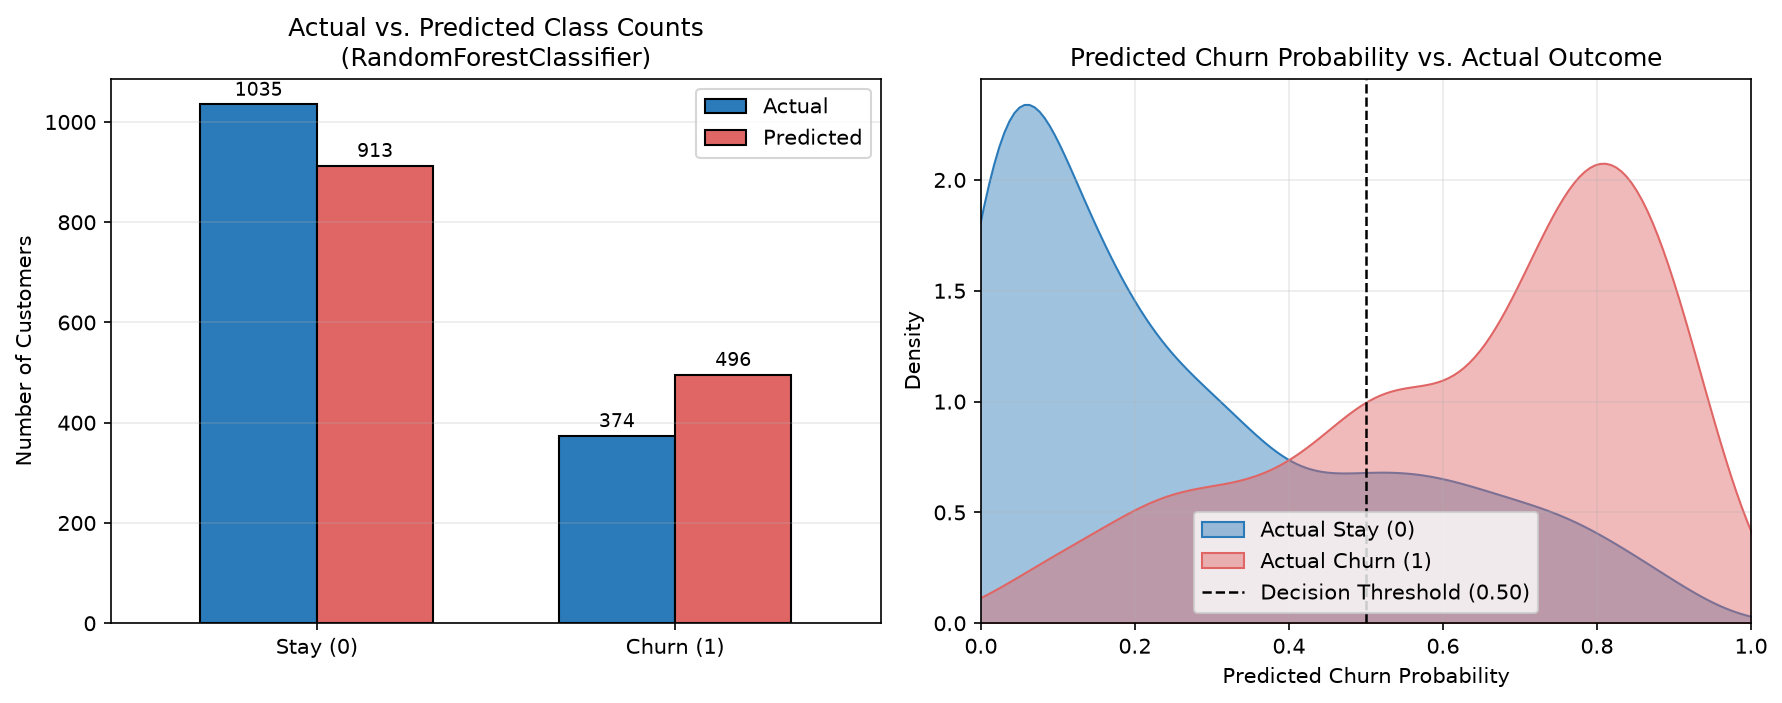


--- model_comparison.png ---


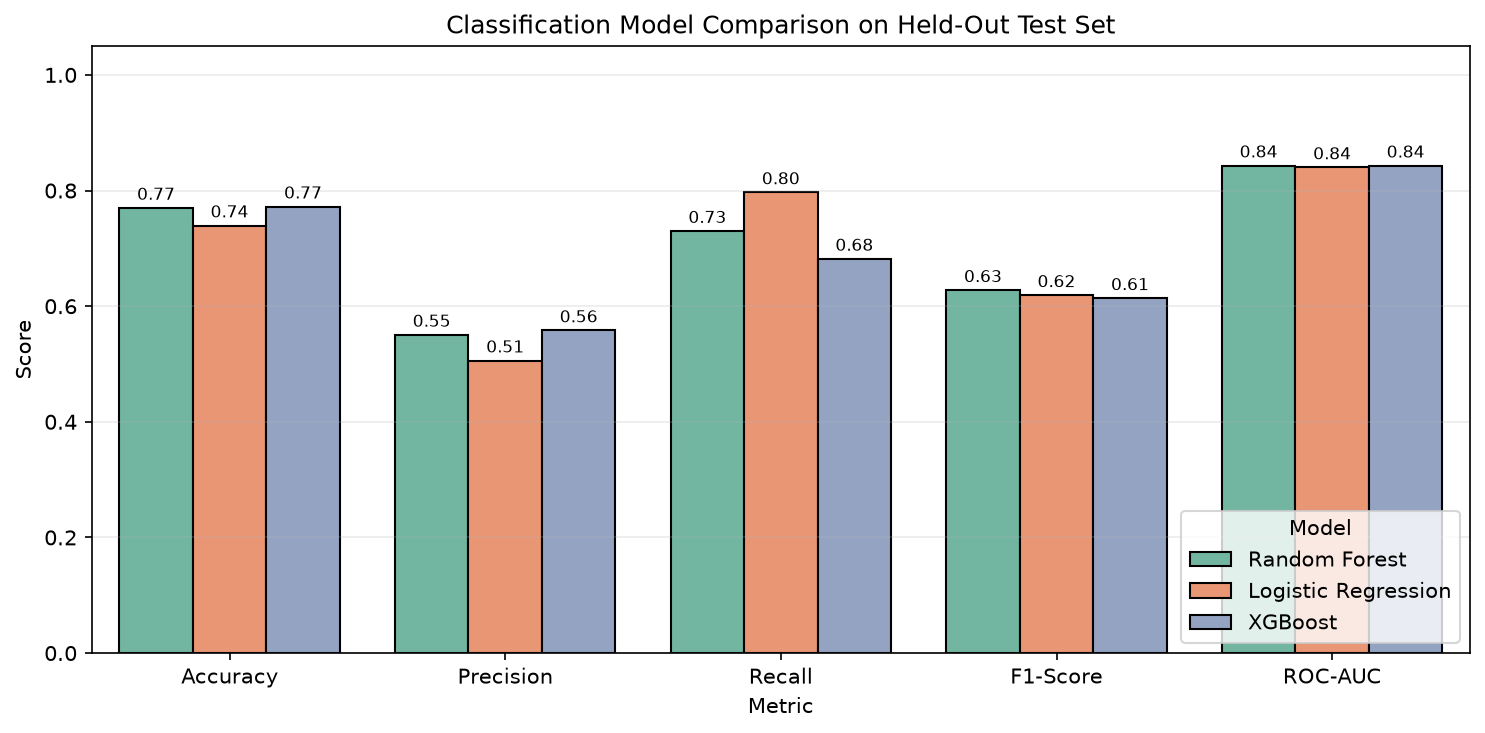


--- feature_importance.png ---


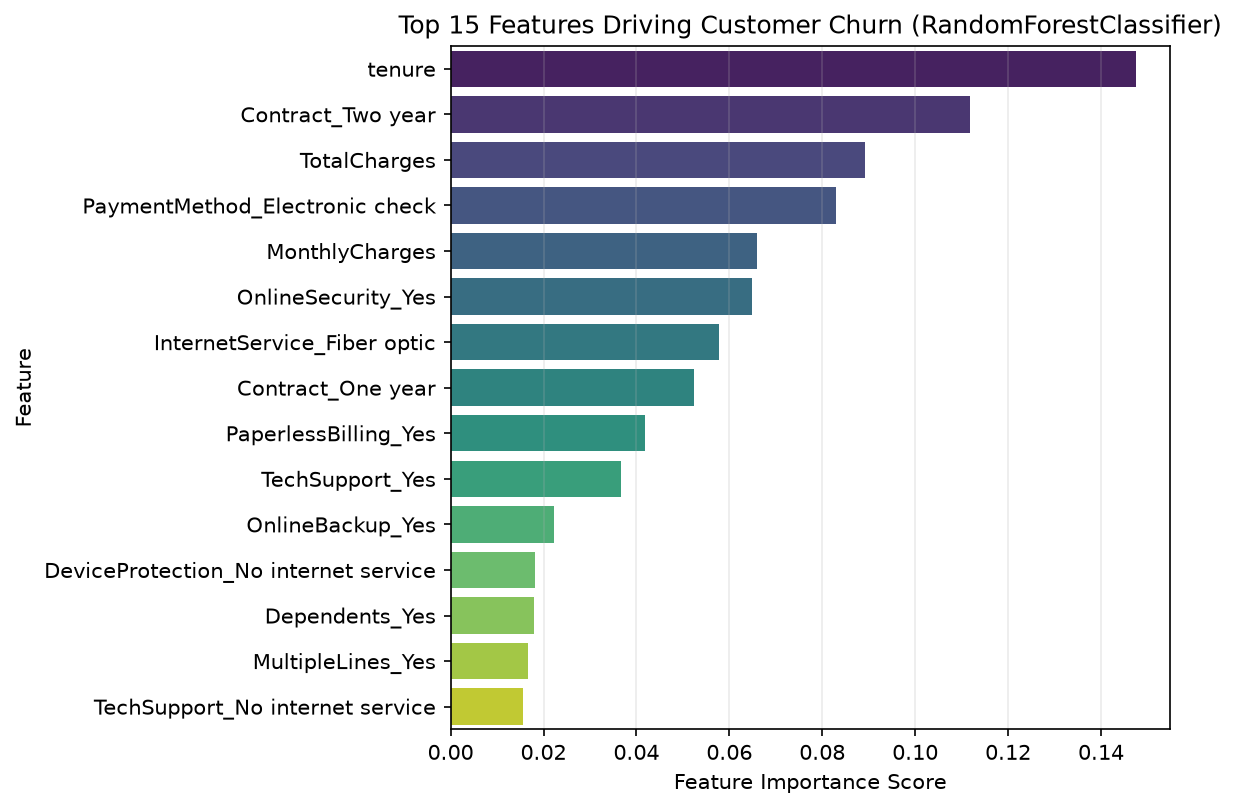

In [4]:
metrics_summary = evaluate_classification(
    pipeline_path=MODEL_OUT,
    X_test=X_test,
    y_test=y_test,
    results_dir=RESULTS_DIR,
    fitted_models=fitted_models,
    comparison_df=comparison_df
)
print("Champion Evaluation Metrics on Held-Out Test Set:")
for k, v in metrics_summary.items():
    print(f"  {k}: {v}")

for img_name in ["confusion_matrix.png", "roc_curve.png", "predicted_vs_actual.png", "model_comparison.png", "feature_importance.png"]:
    img_path = os.path.join(RESULTS_DIR, img_name)
    if os.path.exists(img_path):
        print(f"\n--- {img_name} ---")
        display(Image(filename=img_path))

## 4. Test New Customer Prediction Engine (`predict_new_customer` & `predict_churn`)

In [5]:
high_risk_customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 70.7, "TotalCharges": 151.65
}

loyal_customer = {
    "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes",
    "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
    "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Two year",
    "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)",
    "MonthlyCharges": 55.0, "TotalCharges": 3300.0
}

print("High-Risk Customer Prediction:", predict_new_customer(high_risk_customer))
print("Loyal Customer Prediction:", predict_new_customer(loyal_customer))

High-Risk Customer Prediction: {'prediction': 'Customer Likely to Churn', 'churn_probability': 0.8460475952682424, 'churn_flag': 1, 'model_used': 'RandomForestClassifier'}


Loyal Customer Prediction: {'prediction': 'Customer Likely to Stay', 'churn_probability': 0.0483646747537224, 'churn_flag': 0, 'model_used': 'RandomForestClassifier'}


## 5. Feature Selection Analysis (`mutual_info_classif` & `SelectFromModel`)

In [6]:
from sklearn.feature_selection import mutual_info_classif, SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score

prep_fitted = best_pipeline.named_steps["preprocessor"]
feat_names = [f.replace("num__", "").replace("cat__", "") for f in prep_fitted.get_feature_names_out()]
X_tr_mi = prep_fitted.transform(X_train)
mi_scores = mutual_info_classif(X_tr_mi, y_train, random_state=42)
mi_df = pd.DataFrame({"Feature": feat_names, "Mutual_Info": mi_scores}).sort_values("Mutual_Info", ascending=False)
print("Top 10 Features by Mutual Information (computed strictly on X_train):")
display(mi_df.head(10))

selector = SelectFromModel(best_pipeline.named_steps["classifier"], threshold="median", prefit=True)
X_tr_sel = selector.transform(X_tr)
X_te_sel = selector.transform(X_te)
rf_sel = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf_sel.fit(X_tr_sel, y_tr)
print(f"Selected {X_tr_sel.shape[1]}/{X_tr.shape[1]} features -> Test F1: {f1_score(y_te, rf_sel.predict(X_te_sel)):.4f}, Test ROC-AUC: {roc_auc_score(y_te, rf_sel.predict_proba(X_te_sel)[:, 1]):.4f}")

Top 10 Features by Mutual Information (computed strictly on X_train):


,Feature,Mutual_Info
0,tenure,0.069680
25,Contract_Two year,0.058596
1,MonthlyCharges,0.050519
28,PaymentMethod_Electronic check,0.044712
10,InternetService_Fiber optic,0.043803
20,StreamingTV_No internet service,0.040705
2,TotalCharges,0.038421
22,StreamingMovies_No internet service,0.038142
18,TechSupport_No internet service,0.036675
16,DeviceProtection_No internet service,0.033925


Selected 15/30 features -> Test F1: 0.6257, Test ROC-AUC: 0.8403
